# Research Experiment 02 — SPY Volatility Forecasting with GARCH(1,1)

**Repository:** `apimaezekiel-arch/regime-aware-option-pricing`  
**Research status:** Empirical workflow, not yet executed or peer reviewed.

**Question:** Does a GARCH(1,1) specification improve one-trading-day-ahead conditional variance forecasts over an EWMA(λ = 0.94) benchmark for SPY returns?

This notebook downloads publicly accessible **SPY daily historical prices**, estimates conditional variance using an expanding/rolling historical window, evaluates genuinely out-of-sample forecasts, and draws figures. **SPY share prices are not option quotes**: this experiment does not evaluate option-pricing errors or calibrate Heston. Future experiments can do that using historical option chains.

**Data note:** Yahoo Finance via `yfinance` is a convenient research source, subject to availability, changes, and usage terms. No prices or results are bundled. Do not claim results without successfully running the notebook.

## 1 · Environment (Colab / Jupyter)
Run the installation cell once. In Colab choose **Runtime → Run all**. Installation and the price download require an internet connection. If pip indicates a restart is needed, restart the runtime and rerun.

In [10]:
%pip -q install "yfinance>=0.2.50" "arch>=7.0" "pandas>=2.0" "numpy>=1.24" "matplotlib>=3.7"

In [11]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from arch import arch_model
from IPython.display import display

plt.rcParams.update({"figure.figsize": (11, 5), "axes.grid": True})
print("pandas:", pd.__version__, "yfinance:", yf.__version__)

pandas: 2.2.3 yfinance: 0.2.66


## 2 · Obtain SPY market observations

The end date is **exclusive** in `yfinance`. We request adjusted closing prices (accounting for splits and distributions) with `auto_adjust=True`, so `Close` represents the adjusted series. SPY is a US ETF; its trading calendar has holidays and missing weekends. Avoid filling absent trading days with synthetic prices.

In [12]:
TICKER = "SPY"
START = "2020-01-01"
END = "2026-01-01"       # exclusive; change if you want a different sample
TEST_DAYS = 120          # last 120 trading sessions, not calendar days
WINDOW = 750             # number of past daily returns per estimation
REFIT_EVERY = 10         # periodically re-estimate parameters using PAST observations
EWMA_LAMBDA = 0.94

raw = yf.download(TICKER, start=START, end=END, auto_adjust=True,
                  progress=False, threads=False)
if raw.empty:
    raise RuntimeError("No SPY observations downloaded; check internet access, ticker, or Yahoo availability.")
close = raw["Close"]
if isinstance(close, pd.DataFrame):  # yfinance sometimes returns MultiIndex columns
    close = close[TICKER] if TICKER in close.columns else close.iloc[:, 0]
close = pd.to_numeric(close, errors="coerce").dropna().sort_index()
close = close.loc[~close.index.duplicated(keep="first")]
returns = (100 * np.log(close / close.shift(1))).dropna().rename("daily_log_return_pct")
if len(returns) <= WINDOW + TEST_DAYS:
    raise ValueError(f"Need more than WINDOW + TEST_DAYS={WINDOW+TEST_DAYS} returns, got {len(returns)}")
print(f"Observations: {len(close)} prices, {len(returns)} returns")
print(f"First/last observation: {close.index.min().date()} → {close.index.max().date()}")
display(close.tail().to_frame("adjusted_close_usd"))

Observations: 1508 prices, 1507 returns
First/last observation: 2020-01-02 → 2025-12-31


,adjusted_close_usd
Date,
2025-12-24,685.029480
2025-12-26,684.960022
2025-12-29,682.519043
2025-12-30,681.685547
2025-12-31,676.635010


## 3 · Explore returns and their volatility

Returns are computed as \(r_t=100\log(P_t/P_{t-1})\) in **percent units**. Daily conditional variance estimates therefore have **percent-squared** units. Large absolute daily returns are not the same thing as directly observing latent daily variance.

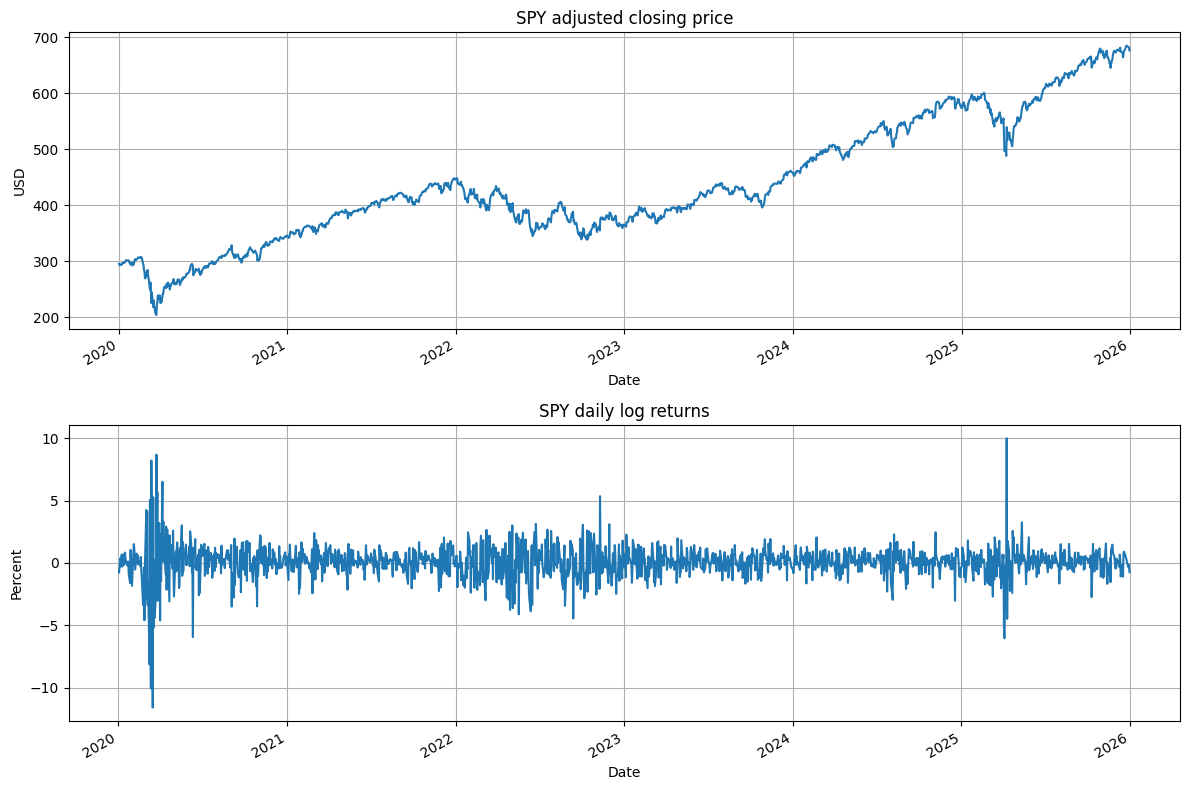

Return descriptive statistics (percent):


,value
count,1507.000000
mean,0.054999
std,1.310053
min,-11.588624
25%,-0.485630
50%,0.097208
75%,0.681084
max,9.986284


In [13]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=False)
close.plot(ax=axes[0], title="SPY adjusted closing price")
axes[0].set_ylabel("USD")
returns.plot(ax=axes[1], title="SPY daily log returns")
axes[1].set_ylabel("Percent")
plt.tight_layout()
plt.show()
print("Return descriptive statistics (percent):")
display(returns.describe().to_frame("value"))

## 4 · Forecast design: no information leakage

For each held-out day \(t\), forecast \(\sigma_t^2\) using **only returns through \(t-1\)**. Within blocks of ten test days, GARCH parameters are estimated once from the most recent 750 observed past returns, and the variance recursion is updated sequentially as new daily returns become observable. This is a *periodic rolling refit* forecast protocol, not a daily refit.

We estimate a zero-mean, Gaussian GARCH(1,1) model:

\[
\sigma_t^2=\omega+\alpha\,r_{t-1}^2+\beta\,\sigma_{t-1}^2.
\]

The EWMA benchmark uses the same timing: \(h_t=\lambda h_{t-1}+(1-\lambda)r_{t-1}^2\), where \(\lambda=0.94\). A zero-mean assumption is transparent and can be relaxed in later research.

In [14]:
def fit_garch(past_returns: pd.Series):
    """Fit only on past observations, return parameters and last in-sample variance."""
    fit = arch_model(past_returns.to_numpy(dtype=float), mean="Zero", vol="GARCH",
                     p=1, q=1, dist="normal", rescale=False).fit(
                         disp="off", show_warning=False)
    params = fit.params
    omega, alpha, beta = (float(params[k]) for k in ("omega", "alpha[1]", "beta[1]"))
    last_h = float(fit.conditional_volatility[-1] ** 2)
    if not all(np.isfinite([omega, alpha, beta, last_h])):
        raise RuntimeError("GARCH fit produced nonfinite values")
    return omega, alpha, beta, last_h


def run_forecast_experiment(r: pd.Series, window=750, test_days=120,
                            refit_every=10, lam=0.94):
    if not (0 < lam < 1 and window > 50 and 0 < test_days < len(r)-window
            and refit_every >= 1):
        raise ValueError("Invalid window, test_days, refit_every, or lambda")
    r = r.dropna().astype(float)
    first_test = len(r) - test_days
    # At the start of the test period, EWMA is initialized using TRAINING data only.
    ewma_h = float(r.iloc[first_test-window:first_test].var(ddof=0))
    for observed in r.iloc[first_test-window:first_test]:
        ewma_h = lam * ewma_h + (1-lam) * float(observed)**2
    rows = []
    for j in range(test_days):
        t = first_test + j
        if j % refit_every == 0:
            history = r.iloc[t-window:t]
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")
                omega, alpha, beta, last_h = fit_garch(history)
            garch_h = omega + alpha * float(history.iloc[-1])**2 + beta * last_h
        # garch_h and ewma_h forecast day t: no returns[t] used yet.
        rows.append({"date": r.index[t], "actual_return_pct": float(r.iloc[t]),
                     "garch_variance": garch_h, "ewma_variance": ewma_h,
                     "omega": omega, "alpha": alpha, "beta": beta})
        observed = float(r.iloc[t])  # available AFTER the forecasts are recorded
        garch_h = omega + alpha * observed**2 + beta * garch_h
        ewma_h = lam * ewma_h + (1-lam) * observed**2
    out = pd.DataFrame(rows).set_index("date")
    if not np.isfinite(out.select_dtypes(include=["number"]).to_numpy()).all():
        raise RuntimeError("Nonfinite forecasts detected")
    if (out[["garch_variance", "ewma_variance"]] <= 0).any().any():
        raise RuntimeError("Nonpositive predicted variance detected")
    return out

pred = run_forecast_experiment(returns, window=WINDOW, test_days=TEST_DAYS,
                               refit_every=REFIT_EVERY, lam=EWMA_LAMBDA)
pred["squared_return"] = pred["actual_return_pct"] ** 2
pred["garch_vol_pct"] = np.sqrt(pred["garch_variance"])
pred["ewma_vol_pct"] = np.sqrt(pred["ewma_variance"])
display(pred.head())

,actual_return_pct,garch_variance,ewma_variance,omega,alpha,beta,squared_return,garch_vol_pct,ewma_vol_pct
date,,,,,,,,,
2025-07-14,0.190654,0.486354,0.711012,0.031828,0.10341,0.868182,0.036349,0.697391,0.843216
2025-07-15,-0.428248,0.457830,0.670533,0.031828,0.10341,0.868182,0.183397,0.676631,0.818861
2025-07-16,0.333775,0.448272,0.641304,0.031828,0.10341,0.868182,0.111405,0.669531,0.800815
2025-07-17,0.610092,0.432529,0.609511,0.031828,0.10341,0.868182,0.372213,0.657670,0.780712
2025-07-18,-0.073255,0.445832,0.595273,0.031828,0.10341,0.868182,0.005366,0.667706,0.771539


## 5 · Out-of-sample evaluation

Because true daily conditional variance is unobservable, we use squared realized daily returns as a **noisy variance proxy**. Report both MSE and QLIKE; neither is a perfect direct measurement of latent variance. QLIKE uses \(\log(h_t)+r_t^2/h_t\), omitting the constant shared by methods. Lower loss is better. A proper study should also investigate alternative volatility proxies, uncertainty, structural breaks, and robustness to sample choice.

In [15]:
def score_variance(actual_squared, forecast_h):
    x = np.asarray(actual_squared, dtype=float)
    h = np.asarray(forecast_h, dtype=float)
    if np.any(h <= 0) or not np.isfinite(h).all():
        raise ValueError("Forecast variance must be positive and finite")
    return {"MSE_variance": float(np.mean((x-h)**2)),
            "QLIKE": float(np.mean(np.log(h) + x/h))}

scores = pd.DataFrame({
    "GARCH(1,1)": score_variance(pred["squared_return"], pred["garch_variance"]),
    "EWMA(0.94)": score_variance(pred["squared_return"], pred["ewma_variance"]),
}).T
print(f"Evaluation sample: {pred.index.min().date()} to {pred.index.max().date()}")
display(scores)
print("Descriptive comparison only: these losses do NOT establish statistical significance.")

Evaluation sample: 2025-07-14 to 2025-12-31


,MSE_variance,QLIKE
"GARCH(1,1)",0.848634,0.328409
EWMA(0.94),0.845800,0.399808


Descriptive comparison only: these losses do NOT establish statistical significance.


## 6 · Visual evidence

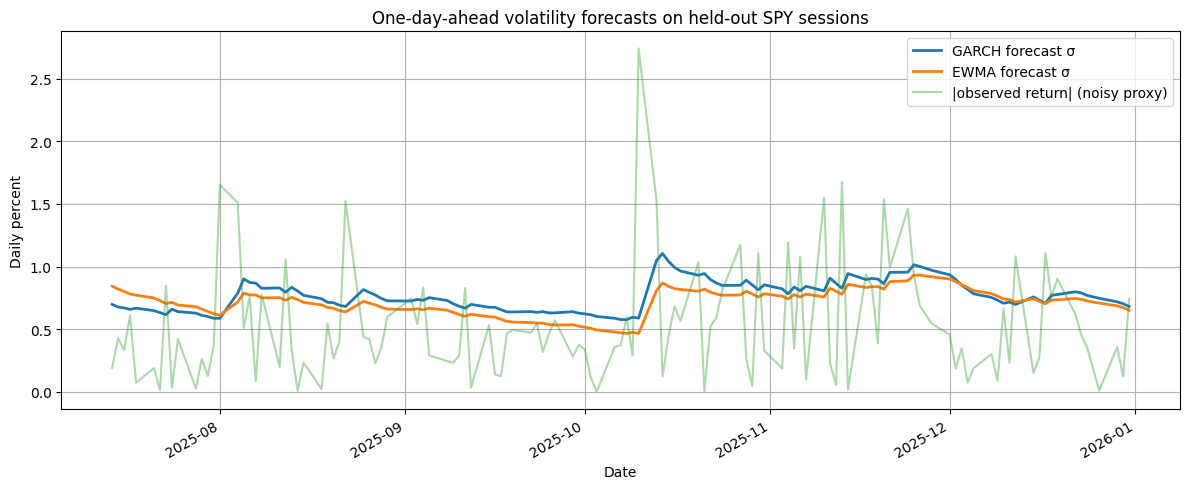

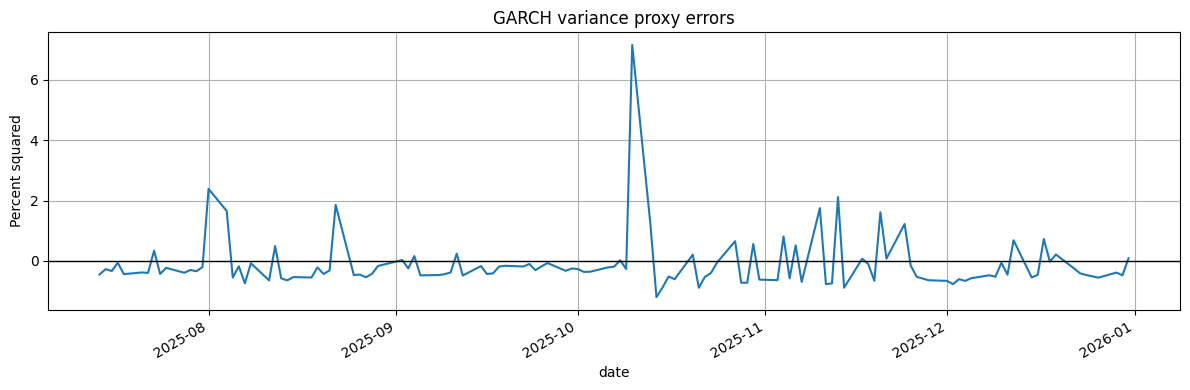

In [16]:
fig, ax = plt.subplots(figsize=(12, 5))
pred["garch_vol_pct"].plot(ax=ax, label="GARCH forecast σ", lw=2)
pred["ewma_vol_pct"].plot(ax=ax, label="EWMA forecast σ", lw=2)
pred["actual_return_pct"].abs().plot(ax=ax, label="|observed return| (noisy proxy)", alpha=.4)
ax.set(title="One-day-ahead volatility forecasts on held-out SPY sessions",
       ylabel="Daily percent", xlabel="Date")
ax.legend()
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(12, 4))
(pred["squared_return"] - pred["garch_variance"]).plot(ax=ax, label="Squared return − GARCH variance")
ax.axhline(0, color="black", linewidth=1)
ax.set(title="GARCH variance proxy errors", ylabel="Percent squared")
plt.tight_layout()
plt.show()

## 7 · Save your outputs (optional)

When run in Colab, output files appear in the session's Files pane; download these if you want to keep them. Do **not** commit automatically downloaded market data or claim that this notebook is an option-pricing experiment. Generated model results should be clearly dated and reproducible.

In [17]:
OUTPUT_DIR = Path("results")
OUTPUT_DIR.mkdir(exist_ok=True)
pred.to_csv(OUTPUT_DIR / "spy_garch_ewma_test_predictions.csv")
scores.to_csv(OUTPUT_DIR / "spy_garch_ewma_scores.csv")
print("Saved results in:", OUTPUT_DIR.resolve())

Saved results in: /content/results
